# 10 · Radar vs gauges

*Two instruments that measure rain in completely different ways, and what each gets wrong.*

Notebook 02 ended with a puzzle. In the October 2021 storm the radar saw about half the rain that the gauge-blended product had. This notebook asks the question properly, over four years and every station that has a rain gauge.

A **rain gauge** catches what falls into a funnel about 20 cm across. Airport stations use a heated **tipping bucket**: a small seesaw that tips each time it collects 0.01 inch (0.25 mm) and counts the tips. It measures one spot, and it has known weaknesses. Wind blows drops past the funnel, the bucket loses water mid-tip in a downpour, and snow has to melt before it counts. A National Academies review found ASOS gauges catching 2–10% less than a manual gauge in heavy rain and much less in snow ([NRC 2012](https://www.nap.edu/read/13216/chapter/13)).

**MRMS radar-only** turns reflectivity from nearby radars into rain on a 1 km grid. It sees everywhere at once but from above. Notebook 02 showed why that matters. The beam climbs with distance and mountains block it.

So neither one is the truth. Comparing them shows where each fails. For radar the expectation is the geometry. For gauges it's the occasional broken sensor that only a second witness can catch, the same idea as quarantine in notebook 05.

Rain also needs its own scores. Most hours are dry and a few are very wet, so a squared error is dominated by a handful of storms. We split the question three ways: did it rain (detection), how much (totals), and what kind of day was it (**SEEPS**, the rain score WeatherBench 2 uses).

In [1]:
# Setup: identical in every notebook. Data lives in ../data, which git ignores.
import os
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data"))
os.makedirs(DATA_DIR, exist_ok=True)
print("Data directory:", DATA_DIR)

Data directory: /Users/ashu/Workspace/weather-data-lab/data


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from wxlab import stations as st, rain

plt.rcParams["figure.dpi"] = 80
points = pd.read_parquet(Path(DATA_DIR) / "reference" / "station_points.parquet")
names = st.load_station_history(Path(DATA_DIR) / "meta").drop_duplicates("station_id").set_index("station_id")["name"].str.title()

## Step 1 · Match gauge hours to radar hours

`rain.extract_mrms_points` read every hourly MRMS file for 2021–2024 (two products, about 70,000 files) and kept the value in the 1 km cell above each station. It decodes each GRIB2 file with ecCodes directly, about 0.17 s per file, and works in units of one product-month so it can be stopped and resumed. It took under an hour on eight cores and is cached.

Timing needs one detail. The station table puts the routine airport report from 22:53 at 23:00, but that report's rain covers roughly 21:53 to 22:53. `rain.load_gauges` shifts it back an hour so it lines up with MRMS's hour from 22:00 to 23:00.

In [3]:
mrms_dir = Path(DATA_DIR) / "work" / "mrms_points"
if len(list(mrms_dir.glob("*/*.parquet"))) < 96:
    rain.extract_mrms_points(Path(DATA_DIR) / "raw", mrms_dir, points)
gauges = rain.load_gauges(Path(DATA_DIR) / "standardized" / "isd")
hourly = rain.match(gauges, rain.load_mrms_points(mrms_dir))
beam = rain.lowest_beam(points, rain.radar_sites())
hourly = hourly.merge(beam, on="station_id")
ok = hourly[~hourly.noaa_suspect]                         # NOAA's own suspect codes set aside for now
print(f"{len(hourly):,} matched station-hours at {hourly.station_id.nunique()} stations with a gauge")

2,824,121 matched station-hours at 135 stations with a gauge


## Step 2 · Did it rain?

Count an hour as wet at 0.25 mm, the smallest amount a gauge can report. With the gauge as the reference, three numbers summarise detection. **POD** (probability of detection) is the share of the gauge's wet hours radar also saw. **FAR** (false alarm ratio) is the share of radar's wet hours the gauge called dry. **CSI** (critical success index) combines both.

In [4]:
pd.DataFrame({c: rain.detection(ok.gauge, ok[c]) for c in ["radar_only", "radar_only_3x3", "multi_sensor"]}).T[["pod", "far", "csi"]].round(3)

,pod,far,csi
radar_only,0.691,0.152,0.615
radar_only_3x3,0.698,0.151,0.621
multi_sensor,0.778,0.144,0.688


Radar-only catches about 7 in 10 of the gauge's wet hours, and about 1 in 7 of its own wet hours were dry at the gauge. Averaging the 3 × 3 cells around the station barely changes it, so small position errors aren't the problem. The gauge-blended product catches more, as it should, but it isn't an independent check because it may have used these same gauges.

## Step 3 · How much? It depends on how high the beam is

Over all matched hours, radar-only adds up to about 80% of what the gauges caught. That average hides a strong pattern. For each station, `rain.lowest_beam` finds the nearby radar whose 0.5° beam passes lowest above the ground there, using the 4/3 Earth model from notebook 02. It ignores mountains in the way, so in rough terrain the real beam is higher still.

,stations,radar / gauge,POD
beam above station (km),,,
< 0.5,27.0,0.92,0.75
0.5–1,34.0,1.00,0.76
1–1.5,33.0,0.81,0.73
1.5–2,26.0,0.71,0.66
> 2,15.0,0.43,0.46


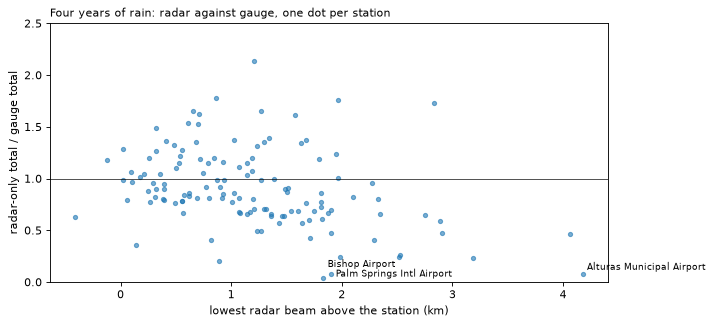

In [5]:
bins = pd.cut(ok.beam_m, [-1e4, 500, 1000, 1500, 2000, 1e4], labels=["< 0.5", "0.5–1", "1–1.5", "1.5–2", "> 2"])
by_beam = ok.groupby(bins, observed=True).apply(lambda x: pd.Series({
    "stations": x.station_id.nunique(),
    "radar / gauge": x.radar_only.sum() / x.gauge.sum(),
    "POD": rain.detection(x.gauge, x.radar_only)["pod"]})).rename_axis("beam above station (km)")

per_station = ok.groupby("station_id").agg(gauge=("gauge", "sum"), radar=("radar_only", "sum"), beam=("beam_m", "first"))
per_station = per_station[per_station.gauge > 100].assign(ratio=lambda d: d.radar / d.gauge)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.scatter(per_station.beam / 1000, per_station.ratio, s=14, alpha=0.6)
ax.axhline(1, color="k", lw=0.6)
for sid, dy in zip(per_station.nsmallest(3, "ratio").index, [10, -2, 4]):
    r = per_station.loc[sid]; ax.annotate(names.get(sid, sid), (r.beam / 1000, r.ratio), fontsize=8, xytext=(4, dy), textcoords="offset points")
ax.set_xlabel("lowest radar beam above the station (km)"); ax.set_ylabel("radar-only total / gauge total")
ax.set_ylim(0, 2.5); ax.set_title("Four years of rain: radar against gauge, one dot per station", loc="left", fontsize=10)
by_beam.round(2)

Where the beam passes within half a kilometre of the ground, radar-only gets about 90% of the gauge total and detection is as good as anywhere. Above 2 km it gets less than half and misses more than half of the wet hours. That's the "half the rain" from notebook 02, now explained as geometry across 130 stations. NOAA's evaluations in California's coastal mountains point at the same two causes, beams blocked by terrain and shallow rain that forms under the beam ([Cifelli et al., NOAA](https://repository.library.noaa.gov/view/noaa/14632)).

The worst stations have names. Bishop sits in the Owens Valley east of the Sierra Nevada. Palm Springs sits under the San Jacinto Mountains. Alturas is in the far north-east, more than 4 km below the nearest beam. The mountains between them and every radar block the low beams, so radar sees almost none of their rain. These are **radar blind spots**, and a dataset built on radar rain needs to know where they are.

The scatter also has dots well above 1, where radar sees more than the gauge. Some are gauges that under-catch or go quiet, which is the next step.

## Step 4 · What kind of day was it? SEEPS

Hourly matching punishes small timing errors. **SEEPS** (Stable Equitable Error in Probability Space) judges daily totals by category instead: dry, light or heavy. The line between light and heavy is set separately at each station, so that light days are twice as common as heavy ones there. That makes "heavy" mean the same thing in a desert and on the coast. Missing a heavy day costs more than mistaking light for dry, and the weights are chosen so that always forecasting the climatology scores about 1 ([Rodwell et al. 2010](https://www.ecmwf.int/sites/default/files/elibrary/2010/11988-new-equitable-score-suitable-verifying-precipitation-nwp.pdf)).

SEEPS is only defined where the share of dry days, p1, lies between 0.1 and 0.85. WeatherBench 2 leaves other places out ([WB2 docs](https://weatherbench2.readthedocs.io/en/latest/_autosummary/weatherbench2.metrics.SEEPS.html)).

In [6]:
daily = rain.daily(ok, ["gauge", "radar_only", "multi_sensor"])
thr = rain.seeps_thresholds(daily, "gauge")
usable = rain.seeps_stations(thr)
print(f"{len(thr)} stations with enough complete days; {len(usable)} have p1 in [0.1, 0.85]; median p1 = {thr.p1.median():.2f}")
d = daily.merge(usable, on="station_id")
scores = {c: rain.seeps(d.gauge, d[c], d.p1, d.heavy_mm).mean() for c in ["radar_only", "multi_sensor"]}
scores["always dry"] = rain.seeps(d.gauge, np.zeros(len(d)), d.p1, d.heavy_mm).mean()
pd.Series(scores, name="mean SEEPS (lower is better)").round(3).to_frame()

112 stations with enough complete days; 25 have p1 in [0.1, 0.85]; median p1 = 0.87


,mean SEEPS (lower is better)
radar_only,0.152
multi_sensor,0.112
always dry,0.166


Two surprises. California is too dry for SEEPS at most of its stations. Rain falls on only 13% of days at the median station, so just 25 of 112 stations qualify. A global benchmark would simply skip most of this state.

Where SEEPS does apply, radar-only only just beats the lazy forecast of "always dry". Its missed rainy days and its false light-rain days cost nearly as much as never predicting rain at all. Blending in gauges brings the score down by about a quarter.

## Step 5 · Radar as a witness against the gauge

Flip the question around. When a gauge reports a downpour of 25 mm or more in an hour and the radar cell above it has less than 2.5 mm, one of them is wrong. Outside the known blind spots radar rarely misses a downpour completely. `rain.gauge_witness` lists those hours, including the ones NOAA marked as suspect.

In [7]:
w = rain.gauge_witness(hourly)
summary = w.groupby("station_id").agg(hours=("gauge", "size"), max_gauge=("gauge", "max"),
                                      radar_at_max=("radar_only", "first"), noaa_passed=("noaa_suspect", lambda s: int((~s).sum())))
summary.insert(0, "name", summary.index.map(names))
summary.join(beam.set_index("station_id").beam_m.round(-2)).sort_values("hours", ascending=False).head(8)

,name,hours,max_gauge,radar_at_max,noaa_passed,beam_m
station_id,,,,,,
72065200433,Bridgeport Sonora Junction,13,168.4,0.8,12,1700.0
74516023202,Travis Air Force Base,8,264.2,0.9,5,400.0
72595724215,Mount Shasta,3,34.8,0.9,3,2500.0
72383023187,Sandberg,2,41.1,0.0,2,100.0
72033353175,Corona Municipal Airport,1,25.4,0.0,1,900.0
72289523243,Lompoc Airport,1,25.1,0.0,1,600.0
72389693144,Visalia Municipal Airport,1,25.4,0.0,1,200.0
72392623136,Camarillo Airport,1,52.1,0.0,1,1100.0


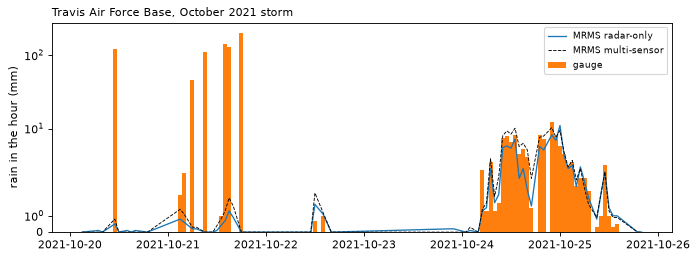

In [8]:
sid = "74516023202"                                      # Travis Air Force Base
x = hourly[(hourly.station_id == sid) & hourly.time.between("2021-10-20", "2021-10-26", inclusive="left")]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(x.time, x.gauge, width=1 / 24, label="gauge", color="tab:orange")
ax.plot(x.time, x.radar_only, color="tab:blue", lw=1.2, label="MRMS radar-only")
ax.plot(x.time, x.multi_sensor, color="k", lw=0.8, ls="--", label="MRMS multi-sensor")
ax.set_yscale("symlog", linthresh=5); ax.set_ylabel("rain in the hour (mm)")
ax.set_title(f"{names.get(sid)}, October 2021 storm", loc="left", fontsize=10); ax.legend(fontsize=8)

Travis Air Force Base is the clearest case, and its radar beam passes only 400 m above it, so radar sees it well. On 20 and 21 October 2021 its gauge reported single hours of 100 mm and more, which would be among the heaviest rain ever measured in California, while radar shows a millimetre or two of light rain. Then on the 24th the real storm arrives and the gauge tracks the radar closely, hour by hour. The gauge works most of the time and spikes now and then. NOAA marked the largest spikes suspect but passed others above 100 mm. Nothing about the gauge alone says which hours are wrong. The radar does.

The list has other kinds too. Bridgeport, a high Sierra station, reported hours of 100 mm and more in the March 2023 rain-on-snow storm while radar saw about 1 mm. NOAA passed 12 of those 13 hours. It's probably not rain at all but meltwater from snow on or around the heated gauge, a known weakness of these gauges in snow ([Rasmussen et al. 2012](https://radiometrics.com/wp-content/uploads/2021/10/Rasmussen_BAMS_2012.pdf)). Bishop shows up in the daily version below, and there it's more likely the radar that's blind. A witness check is only as good as its knowledge of where the witness can see. That's why the beam height column belongs next to every flag.

In [9]:
# Daily view of the same idea: a heavy radar day with a gauge at zero, or the reverse.
quiet_gauge = daily[(daily.radar_only >= 10) & (daily.gauge == 0)]
loud_gauge = daily[(daily.gauge >= 25) & (daily.radar_only < 1)]
pd.DataFrame({"radar ≥ 10 mm, gauge 0": quiet_gauge.station_id.map(names).value_counts().head(4),
              "gauge ≥ 25 mm, radar < 1": loud_gauge.station_id.map(names).value_counts().head(4)})

,"radar ≥ 10 mm, gauge 0","gauge ≥ 25 mm, radar < 1"
station_id,,
Bishop Airport,NaN,5.0
Hollister Municipal Airport,NaN,9.0
Lake Tahoe Airport,NaN,3.0
Mcolf Camp Pendleton Red Beach Airport,5.0,NaN
Mount Shasta,NaN,3.0
Naf,1.0,NaN
Naval Auxiliary Landing Fd,2.0,NaN
Yuba Country Airport,6.0,NaN


Only a few dozen station-days in four years disagree that badly, out of about 100,000. Most stations' gauges and the radar tell a consistent story most of the time. The few that don't are a short list worth a person's attention: a gauge that stays at zero through a heavy storm (Yuba County), and one that logs the same 55 mm two days running with nothing on radar (Hollister).

This turns into a QA check for rain the same way notebook 05's checks did for temperature. It has an independent witness, a rule for when they disagree, and a known list of places where the witness is blind.

## What surprised me

**Radar's rain is a function of geometry.** The share of rain it sees falls steadily from about 90% to under half as the beam rises above the ground.

**Radar has blind spots with names.** Bishop, Palm Springs and Alturas sit behind mountains and get almost no radar rain at all.

**California is too dry for the standard rain score.** Only 25 of 112 stations rain often enough for SEEPS to be defined.

**Radar caught gauges that NOAA passed.** Travis Air Force Base reported 100 mm hours of light drizzle, then measured the real storm correctly three days later.

## Check yourself

<details><summary>Why use radar-only and not the multi-sensor product to judge gauges?</summary>
Multi-sensor blends in rain gauges, possibly these same ones. Judging a gauge against a product built partly from that gauge isn't an independent check. That's the same reasoning as using HRRR's forecast rather than its analysis in notebook 03.
</details>

<details><summary>Why does detection get worse as the beam gets higher?</summary>
Light and shallow rain forms in the lowest kilometre or two. A beam passing above it sees nothing, so those hours become misses even though the radar is working perfectly.
</details>

<details><summary>Why is SEEPS undefined where days are almost always dry?</summary>
Its penalties are scaled by the climatological probabilities. When almost every day is dry, a rare wet day gets an enormous weight and the score becomes unstable, so WeatherBench 2 masks those places out.
</details>

New terms from this notebook are in [`docs/glossary.md`](../docs/glossary.md).